
# Books Web Scraping Project

## Project Overview
This project uses Python to scrape book information from [Books to Scrape](https://books.toscrape.com/), a practice website designed for learning web scraping.

## Objectives
- Collect book titles, prices, ratings, and availability.
- Scrape data across multiple pages using pagination.
- Clean and organize the collected data using Pandas.
- Export the scraped data to a CSV file.
- Perform exploratory data analysis (EDA) and visualize book price distributions.

## Tools and Libraries
- Python
- Requests
- BeautifulSoup
- Pandas
- Matplotlib

## Website
[Books to Scrape](https://books.toscrape.com/)

## Project Workflow
1. Send HTTP requests to the website.
2. Parse HTML content using BeautifulSoup.
3. Extract book information from all available pages.
4. Clean and store the data in a Pandas DataFrame.
5. Export the data to CSV.
6. Analyze book prices and visualize the results.

## Dataset
The dataset contains book titles, prices, ratings, and availability collected from the website.

## Final Output
A cleaned CSV dataset and a price distribution visualization.


## 1. Import Libraries

Import the libraries required to send HTTP requests, extract HTML information, 
organize the data, and visualize the results.

In [10]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

## 2. Send HTTP Request

Send a request to Books to Scrape to retrieve the website's HTML.

In [11]:
url = "https://books.toscrape.com/"

response = requests.get(url)

print(response.status_code)

200


## 3. Inspect HTML

Check the website's HTML response to understand its structure before extracting data.

In [12]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.prettify()[:5000])

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!-->
<html class="no-js" lang="en-us">
 <!--<![endif]-->
 <head>
  <title>
   All products | Books to Scrape - Sandbox
  </title>
  <meta content="text/html; charset=utf-8" http-equiv="content-type"/>
  <meta content="24th Jun 2016 09:29" name="created"/>
  <meta content="" name="description"/>
  <meta content="width=device-width" name="viewport"/>
  <meta content="NOARCHIVE,NOCACHE" name="robots"/>
  <!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
  <!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->
  <link href="static/oscar/favicon.ico" rel="shortcut icon"/>
  <link href="static/oscar/css/styles.css" rel="stylesheet" type="tex


## 4. Web Scraping with Pagination

### Objective
Scrape book information from all pages of Books to Scrape.

### Process
1. Start from the first page of the website.
2. Send an HTTP request to download the page HTML.
3. Parse the HTML using BeautifulSoup.
4. Extract each book's title, price, rating, and availability.
5. Find the "Next" link and move to the next page.
6. Repeat until there are no more pages.
7. Count and display the total number of books collected.

### Output
A Python list containing the scraped book information from all pages.


In [13]:
from urllib.parse import urljoin
import time

books = []

current_url = "https://books.toscrape.com/"

page_number = 1

while current_url:

    print(f"Scraping page {page_number}...")

    response = requests.get(current_url, timeout=10)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    book_containers = soup.find_all("article", class_="product_pod")

    for book in book_containers:

        title = book.h3.a["title"]

        price = book.find("p", class_="price_color").text

        rating = book.find("p", class_="star-rating")["class"][1]

        availability = book.find(
            "p", class_="instock availability"
        ).text.strip()

        books.append({
            "title": title,
            "price": price,
            "rating": rating,
            "availability": availability
        })

    print(f"Books collected so far: {len(books)}")

    # Find the next page
    next_link = soup.find("li", class_="next")

    if next_link:
        next_page_url = next_link.find("a")["href"]

        current_url = urljoin(current_url, next_page_url)

        page_number += 1

        time.sleep(1)

    else:
        current_url = None

print("\nScraping completed!")
print("Total number of books:", len(books))


Scraping page 1...
Books collected so far: 20
Scraping page 2...
Books collected so far: 40
Scraping page 3...
Books collected so far: 60
Scraping page 4...
Books collected so far: 80
Scraping page 5...
Books collected so far: 100
Scraping page 6...
Books collected so far: 120
Scraping page 7...
Books collected so far: 140
Scraping page 8...
Books collected so far: 160
Scraping page 9...
Books collected so far: 180
Scraping page 10...
Books collected so far: 200
Scraping page 11...
Books collected so far: 220
Scraping page 12...
Books collected so far: 240
Scraping page 13...
Books collected so far: 260
Scraping page 14...
Books collected so far: 280
Scraping page 15...
Books collected so far: 300
Scraping page 16...
Books collected so far: 320
Scraping page 17...
Books collected so far: 340
Scraping page 18...
Books collected so far: 360
Scraping page 19...
Books collected so far: 380
Scraping page 20...
Books collected so far: 400
Scraping page 21...
Books collected so far: 420
Scrap

## 5. Create DataFrame

Convert the extracted book information into a Pandas DataFrame.

In [14]:
df = pd.DataFrame(books)

df.head()

,title,price,rating,availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


## 6. Data Cleaning

Convert the price column into a numeric format and check for missing values and duplicates.

In [15]:
df["price"] = (df["price"].str.replace("Â£", "", regex=False).astype(float))

df.head()

,title,price,rating,availability
0,A Light in the Attic,51.77,Three,In stock
1,Tipping the Velvet,53.74,One,In stock
2,Soumission,50.10,One,In stock
3,Sharp Objects,47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock


In [16]:
df = df.drop_duplicates()

print(df.isnull().sum())

title           0
price           0
rating          0
availability    0
dtype: int64


## 7. Export Data to CSV

Save the scraped book information into a CSV file.

In [17]:
df.to_csv("databooks.csv", index=False)

print("Data saved successfully!")

Data saved successfully!


## 8. Exploratory Data Analysis

Analyze book prices and ratings to understand the collected data.

In [18]:
print("Number of books:", len(df))

print("Average price:", df["price"].mean())

print("Highest price:", df["price"].max())

print("Lowest price:", df["price"].min())

Number of books: 1000
Average price: 35.07035
Highest price: 59.99
Lowest price: 10.0


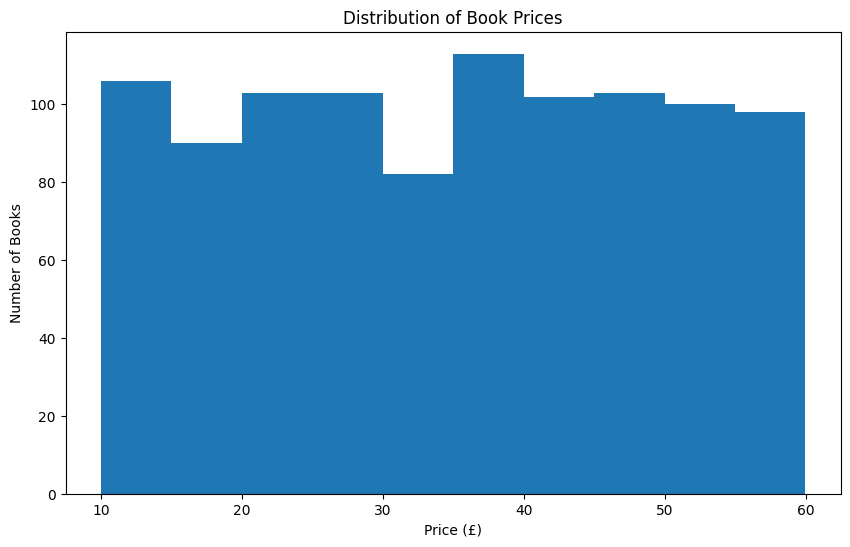

In [19]:
plt.figure(figsize=(10, 6))

plt.hist(df["price"], bins=10)

plt.title("Distribution of Book Prices")

plt.xlabel("Price (£)")

plt.ylabel("Number of Books")

plt.show()

## 9. Conclusion

The project collected book information from Books to Scrape using Requests and BeautifulSoup.

The extracted information was organized and cleaned using Pandas, saved into a CSV file, and analyzed using basic statistics and a price distribution chart.

This project demonstrates the fundamentals of web scraping, data cleaning, and exploratory data analysis.